In [63]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, StandardScaler
from scipy import stats
from sklearn.ensemble import IsolationForest
from sklearn.cluster import DBSCAN
import seaborn as sns
import matplotlib.pyplot as plt

In [64]:
titanic_df = sns.load_dataset('titanic')

missing_values = titanic_df.isnull().sum()
print("Missing values: \n", missing_values)

Missing values: 
 survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [65]:
titanic_df['age'] = titanic_df['age'].fillna(titanic_df['age'].median())
titanic_df['embarked'] = titanic_df['embarked'].fillna(titanic_df['embarked'].mode()[0])

missing_values = titanic_df.isnull().sum()
print("Missing values: \n", missing_values)

Missing values: 
 survived         0
pclass           0
sex              0
age              0
sibsp            0
parch            0
fare             0
embarked         0
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [66]:
titanic_df['FamilySize'] = titanic_df['sibsp'] + titanic_df['parch'] + 1

label_encoder = LabelEncoder()
titanic_df['sex'] = label_encoder.fit_transform(titanic_df['sex'])
titanic_df = pd.get_dummies(titanic_df, columns=['embarked'], prefix=['embarked'])

In [37]:
titanic_df.head()

,survived,pclass,sex,age,sibsp,parch,fare,class,who,adult_male,deck,embark_town,alive,alone,FamilySize,embarked_C,embarked_Q,embarked_S
0,0,3,1,22.0,1,0,7.2500,Third,man,True,NaN,Southampton,no,False,2,False,False,True
1,1,1,0,38.0,1,0,71.2833,First,woman,False,C,Cherbourg,yes,False,2,True,False,False
2,1,3,0,26.0,0,0,7.9250,Third,woman,False,NaN,Southampton,yes,True,1,False,False,True
3,1,1,0,35.0,1,0,53.1000,First,woman,False,C,Southampton,yes,False,2,False,False,True
4,0,3,1,35.0,0,0,8.0500,Third,man,True,NaN,Southampton,no,True,1,False,False,True


In [67]:
titanic_df.drop_duplicates(inplace=True)

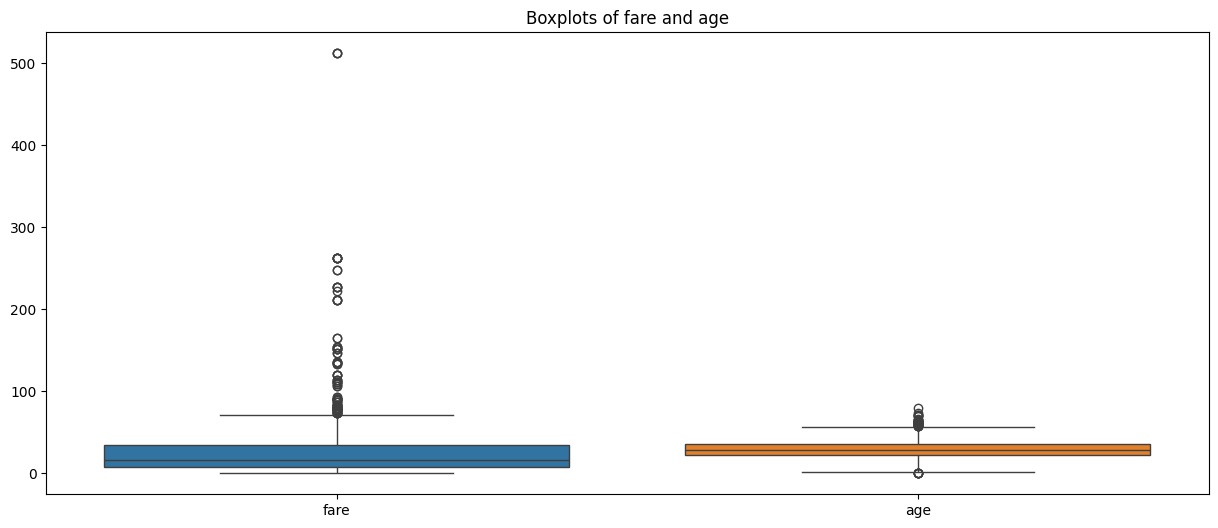

In [68]:
plt.figure(figsize=(15,6))
sns.boxplot(data=titanic_df[['fare','age']])
plt.title('Boxplots of fare and age')
plt.show()

In [69]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(titanic_df[['fare','age']])

In [70]:
z_score = np.abs(stats.zscore(titanic_df[['fare', 'age']]))
outliers_zscore = (z_score > 3).any(axis=1)

iso_forest = IsolationForest(contamination=0.05, random_state=42)
labels_iso = iso_forest.fit_predict(scaled_data)
outliers_iso_forest = (labels_iso == -1)

dbscan = DBSCAN(eps=3, min_samples=2)
labels_db = dbscan.fit_predict(scaled_data)
outliers_dbscan = (labels_db == -1)

Q1 = titanic_df[['fare','age']].quantile(0.25)
Q3 = titanic_df[['fare','age']].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers_fare = (titanic_df['fare'] < lower['fare']) | (titanic_df['fare'] > upper['fare'])
outliers_age = (titanic_df['age'] < lower['age']) | (titanic_df['age'] > upper['age'])

In [77]:
print("Outlier values by z score: \n", np.sum(outliers_zscore))
print("Outlier values by Isolation forest: \n", pd.Series(outliers_iso_forest).value_counts())
print("Outliers by DBSCAN: \n", pd.Series(outliers_dbscan).value_counts())
print("Outliers by IQR: \n")
print("Outliers in fare: ", outliers_fare.sum())
print("Outliers in age: ", outliers_age.sum())

Outlier values by z score: 
 24
Outlier values by Isolation forest: 
 False    742
True      39
Name: count, dtype: int64
Outliers by DBSCAN: 
 False    781
Name: count, dtype: int64
Outliers by IQR: 

Outliers in fare:  102
Outliers in age:  39


In [84]:
all_outliers = (outliers_zscore | outliers_iso_forest | outliers_dbscan | outliers_fare | outliers_age)

In [85]:
clean_titanic_df = titanic_df[~all_outliers].copy()

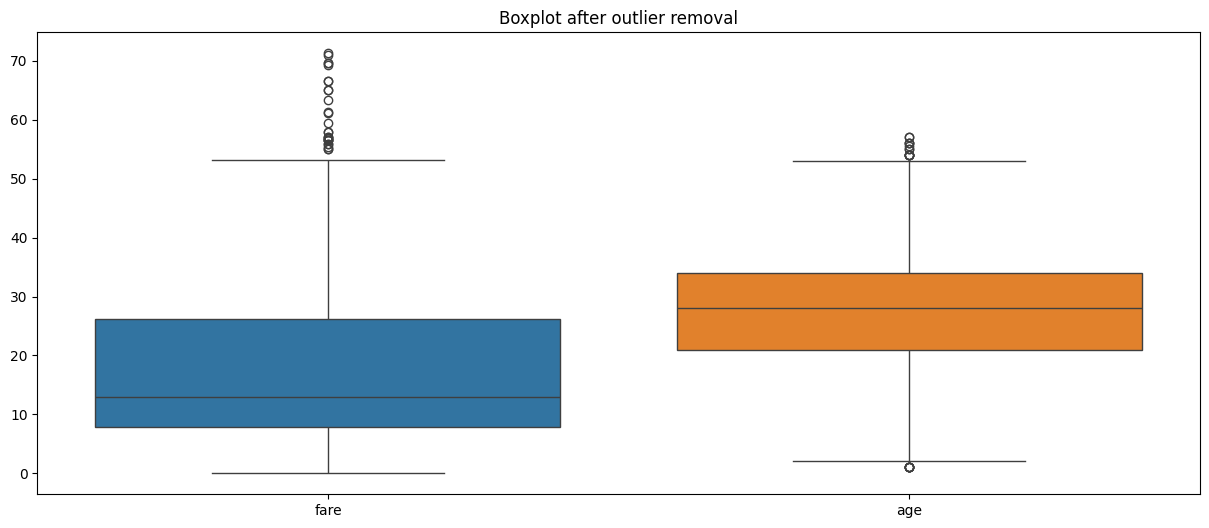

In [86]:
plt.figure(figsize=(15,6))
sns.boxplot(data=clean_titanic_df[['fare','age']])
plt.title('Boxplot after outlier removal')
plt.show()